In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import argparse
import os
import random
import argparse
from karateclub import NetLSD, Graph2Vec, FeatherGraph
from grakel import GraphKernel
import toper

from sklearn.manifold import MDS
from sklearn.decomposition import PCA

from magnipy.magnitude.distances import get_dist

from diversity_curves.process import get_mag_graphs, get_funs_df, get_mag_funs_graphs
from diversity_curves.simulate import simulate_graphs_kwargs
from diversity_curves.classifiers import knn_classifier
from diversity_curves.clustering_performance import compute_clustering_scores_resample, compute_silhouette_score_resamples, compute_rand_agglo, compute_rand_kmeans, all_clustering_results_euclidean
from diversity_curves.baselines.spectral_zoo import est_moment
from diversity_curves.baselines.ph import obtain_input_from_graphs

# scratch space creating script

In [11]:
if True:
    np.random.seed(43)
    random.seed(314)

    # results_dir = args.output_dir
    n_low = 10
    n_high = 30
    n_steps = 1
    n_graphs = 3
    n_reps = [1,3,5]
    n_seeds = 3

    # Setting the parameters as reported in the paper
    model_params = {
        "ER": {
            "ER_probs": [0.75],
            "ER_nps": None,
        },
        "RPG": {
            "RPG_probs": [[0.9, 0.1]],
            "RPG_props": [1 / 3, 1 / 3],
        },
        "SBM": {"SBM_probs": [0.8, 0.05], "SBM_blocks": [[1 / 4, 1 / 4, 1 / 4]]},
        "RG": {"RG_probs": [0.25]},
    }

    # choice of graph metric we use for the spread computation
    graph_metrics = ["shortest_path_distance"]

    # get configuration of all models
    models = list(model_params.keys())
    all_configs = {}
    for model in models:
        model_config = tuple(
            model_params[model][param] for param in model_params[model].keys()
        )
        all_configs[model] = model_config
    configuration = tuple(all_configs[model] for model in models)

    noderange = range(n_low, n_high, n_steps)
    downsample_to = None

    scores = [
        "acc_mean",
        "silh_mean",
        "ari_agglo_mean",
        "db_mean",
        "ch_mean",
        "ari_kmeans_mean",
    ]
    scores_asc = {
        "acc_mean": False,
        "silh_mean": False,
        "ari_agglo_mean": False,
        "db_mean": True,
        "ch_mean": False,
        "ari_kmeans_mean": False,
    }

    res_dict = {}

    # if not os.path.exists(results_dir):
    #     os.makedirs(results_dir, exist_ok=True)

    # generate the graphs of all models and create label per model
    G_nx = []
    Gs = []
    n_nodes = []
    y_models = []
    class_labels = {}
    for i_m, model in enumerate(model_params):
        model_kwargs = model_params[model]
        print(f"model {model} kwargs {model_kwargs}")
        G_nx_model, Gs_model, y_model, y_probs_model, n_nodes_model = (
            simulate_graphs_kwargs(
                model=model,
                n_graphs=n_graphs,
                nodes_range=noderange,
                **model_kwargs,
            )
        )
        G_nx.extend(G_nx_model)
        Gs.extend(Gs_model)
        n_nodes.extend(n_nodes_model)
        y_models.extend([i_m] * len(G_nx_model))
        class_labels[i_m] = model

    upsample_to = max(n_nodes)
    y = y_models
    hue_names = [class_labels[i] for i in y]

    # setting parameters for plots
    sns.set_style("white")
    matplotlib.rcParams.update({"font.size": 20})

    ##################################
    ### computing diversity curves ###
    ##################################

    for metric in graph_metrics:

        for i_seed in range(n_seeds):

            res_dict[(f"divcurves_{metric}", i_seed)] = {}
            res_dict[(f"divcurves_pca_{metric}", i_seed)] = {}

            for n_rep in n_reps:
                
                print(f"Computing MAG with metric: {metric} and nrep: {n_rep} seed: {i_seed}")

                def dist_fn(G):
                    return get_dist(G=G, X=None, X2=None, metric=metric, mode="structure")

                all_spreads, weights_lists = get_mag_graphs(
                    G_nx,
                    dist_fn,
                    ts=[1],
                    upsample_to=upsample_to,
                    downsample_to=downsample_to,
                    n_repeats=n_rep,
                    scores_method='random',
                    mode='structure',
                    set_seed=False
                )

                mag_funs = get_funs_df(all_spreads)
                mag_funs_interpolated = mag_funs.interpolate(method="linear", axis="columns")



                # compute clustering metrics based on euclidean distance of diversity curve vectors
                ari_kmeans_mean, ari_kmeans_std = compute_rand_kmeans(
                    np.array(mag_funs_interpolated), y
                )
                ari_agglo_mean, ari_agglo_std = compute_rand_agglo(
                    np.array(mag_funs_interpolated), y, metric="euclidean"
                )

                means, stds = compute_clustering_scores_resample(
                    np.array(mag_funs_interpolated), y
                )

                (
                    res_dict[(f"divcurves_{metric}", i_seed)][("silh_mean", n_rep)],
                    res_dict[(f"divcurves_{metric}", i_seed)][("db_mean", n_rep, )],
                    res_dict[(f"divcurves_{metric}", i_seed)][("ch_mean", n_rep)],
                ) = means
                (
                    res_dict[(f"divcurves_{metric}", i_seed)][("silh_std", n_rep)],
                    res_dict[(f"divcurves_{metric}", i_seed)][("db_std", n_rep)],
                    res_dict[(f"divcurves_{metric}", i_seed)][("ch_std", n_rep)],
                ) = stds
                res_dict[(f"divcurves_{metric}", i_seed)][("ari_agglo_mean", n_rep)] = ari_agglo_mean
                res_dict[(f"divcurves_{metric}", i_seed)][("ari_agglo_std", n_rep)] = ari_agglo_std
                res_dict[(f"divcurves_{metric}", i_seed)][("ari_kmeans_mean", n_rep)] = ari_kmeans_mean
                res_dict[(f"divcurves_{metric}", i_seed)][("ari_kmeans_std", n_rep)] = ari_kmeans_std

                # computing accuracies
                if n_graphs > 1:
                    test_accs = knn_classifier(
                        np.array(mag_funs_interpolated),
                        np.array(y),
                        precomputed=False,
                        groups=np.array(n_nodes),
                    )
                else:
                    test_accs = knn_classifier(
                        np.array(mag_funs_interpolated), np.array(y), precomputed=False
                    )

                res_dict[(f"divcurves_{metric}", i_seed)][("acc_mean", n_rep)] = np.mean(test_accs)
                res_dict[(f"divcurves_{metric}", i_seed)][("acc_std", n_rep)] = np.std(test_accs)

                # doing PCA with Euclidean distance between the diversity curves
                pca_embedding = PCA(n_components=2)
                X_pca = pca_embedding.fit_transform(np.array(mag_funs_interpolated))

                # computing clustering scores and accuracies on transformed data from PCA
                if n_graphs > 1:
                    test_accs = knn_classifier(
                        X_pca, np.array(y), precomputed=False, groups=np.array(n_nodes)
                    )
                else:
                    test_accs = knn_classifier(X_pca, np.array(y), precomputed=False)

                res_dict[(f"divcurves_pca_{metric}", i_seed)][("acc_mean", n_rep)] = np.mean(test_accs)
                res_dict[(f"divcurves_pca_{metric}", i_seed)][("acc_std", n_rep)] = np.std(test_accs)
                # all_clustering_results_euclidean(f"divcurves_pca_{metric}_nreps_{n_rep}", res_dict, X_pca, y)
                ari_kmeans_mean, ari_kmeans_std = compute_rand_kmeans(
                    X_pca, y
                )
                ari_agglo_mean, ari_agglo_std = compute_rand_agglo(
                    X_pca, y, metric="euclidean"
                )

                means, stds = compute_clustering_scores_resample(
                    X_pca, y
                )

                (
                    res_dict[(f"divcurves_pca_{metric}", i_seed)][("silh_mean", n_rep)],
                    res_dict[(f"divcurves_pca_{metric}", i_seed)][("db_mean", n_rep, )],
                    res_dict[(f"divcurves_pca_{metric}", i_seed)][("ch_mean", n_rep)],
                ) = means
                (
                    res_dict[(f"divcurves_pca_{metric}", i_seed)][("silh_std", n_rep)],
                    res_dict[(f"divcurves_pca_{metric}", i_seed)][("db_std", n_rep)],
                    res_dict[(f"divcurves_pca_{metric}", i_seed)][("ch_std", n_rep)],
                ) = stds
                res_dict[(f"divcurves_pca_{metric}", i_seed)][("ari_agglo_mean", n_rep)] = ari_agglo_mean
                res_dict[(f"divcurves_pca_{metric}", i_seed)][("ari_agglo_std", n_rep)] = ari_agglo_std
                res_dict[(f"divcurves_pca_{metric}", i_seed)][("ari_kmeans_mean", n_rep)] = ari_kmeans_mean
                res_dict[(f"divcurves_pca_{metric}", i_seed)][("ari_kmeans_std", n_rep)] = ari_kmeans_std
                
                # # creating plots
                # fig = sns.scatterplot(
                #     x=X_pca[:, 0], y=X_pca[:, 1], hue=hue_names, palette="tab10"
                # )
                # fig.legend(frameon=False, loc=(1.04, 0), bbox_to_anchor=(1, 0.5))
                # sns.despine()
                # plt.savefig(
                #     results_dir + f"divcurves_pca_{metric}_nreps_{n_rep}.pdf",
                #     dpi=300,
                #     format="pdf",
                #     bbox_inches="tight",
                # )
                # plt.savefig(
                #     results_dir + f"divcurves_pca_{metric}_nreps_{n_rep}.png",
                #     dpi=300,
                #     format="png",
                #     bbox_inches="tight",
                # )
                # plt.close()

        
    # creating dataframes and saving results
    res_df = pd.DataFrame.from_dict(res_dict, orient="index")

    df_n_nodes = pd.DataFrame({"n_nodes": n_nodes})

model ER kwargs {'ER_probs': [0.75], 'ER_nps': None}
model RPG kwargs {'RPG_probs': [[0.9, 0.1]], 'RPG_props': [0.3333333333333333, 0.3333333333333333]}
model SBM kwargs {'SBM_probs': [0.8, 0.05], 'SBM_blocks': [[0.25, 0.25, 0.25]]}
model RG kwargs {'RG_probs': [0.25]}
Computing MAG with metric: shortest_path_distance and nrep: 1 seed: 0
Silhouette Score: 0.422 ± 0.033
Davies-Bouldin Score: 0.754 ± 0.058
Calinski-Harabasz Score: 192.721 ± 33.388
Fold 0: test accuracy = 0.8333 (k=5)
Fold 1: test accuracy = 0.7917 (k=5)
Fold 2: test accuracy = 0.8750 (k=5)
Fold 3: test accuracy = 0.8333 (k=5)
Fold 4: test accuracy = 0.8750 (k=5)
Fold 5: test accuracy = 0.9167 (k=5)
Fold 6: test accuracy = 0.8333 (k=5)
Fold 7: test accuracy = 0.9583 (k=5)
Fold 8: test accuracy = 0.8333 (k=5)
Fold 9: test accuracy = 0.8333 (k=5)

Mean test accuracy: 0.8583
Std test accuracy:  0.0464
Fold 0: test accuracy = 0.8333 (k=5)
Fold 1: test accuracy = 0.7917 (k=5)
Fold 2: test accuracy = 0.9167 (k=5)
Fold 3: test a

In [24]:
pd.MultiIndex.from_product([scores+[score[:-4]+'std' for score in scores],n_reps])

MultiIndex([(       'acc_mean', 1),
            (       'acc_mean', 3),
            (       'acc_mean', 5),
            (      'silh_mean', 1),
            (      'silh_mean', 3),
            (      'silh_mean', 5),
            ( 'ari_agglo_mean', 1),
            ( 'ari_agglo_mean', 3),
            ( 'ari_agglo_mean', 5),
            (        'db_mean', 1),
            (        'db_mean', 3),
            (        'db_mean', 5),
            (        'ch_mean', 1),
            (        'ch_mean', 3),
            (        'ch_mean', 5),
            ('ari_kmeans_mean', 1),
            ('ari_kmeans_mean', 3),
            ('ari_kmeans_mean', 5),
            (        'acc_std', 1),
            (        'acc_std', 3),
            (        'acc_std', 5),
            (       'silh_std', 1),
            (       'silh_std', 3),
            (       'silh_std', 5),
            (  'ari_agglo_std', 1),
            (  'ari_agglo_std', 3),
            (  'ari_agglo_std', 5),
            (         'db_st

In [25]:
res_df.columns = pd.MultiIndex.from_product([scores+[score[:-4]+'std' for score in scores],n_reps])

In [26]:
res_df

acc_mean                        \
                                               1         3           5   
divcurves_shortest_path_distance     0  0.421604  0.754183  192.720745   
divcurves_pca_shortest_path_distance 0  0.434270  0.732491  197.008837   
divcurves_shortest_path_distance     1  0.418545  0.762476  190.735427   
divcurves_pca_shortest_path_distance 1  0.430249  0.742956  194.602720   
divcurves_shortest_path_distance     2  0.418545  0.762476  190.735427   
divcurves_pca_shortest_path_distance 2  0.430249  0.742956  194.602720   

                                       silh_mean                       \
                                               1         3          5   
divcurves_shortest_path_distance     0  0.033456  0.058361  33.387778   
divcurves_pca_shortest_path_distance 0  0.034245  0.058968  34.709484   
divcurves_shortest_path_distance     1  0.033549  0.059957  33.126113   
divcurves_pca_shortest_path_distance 1  0.034384  0.060510  34.370930   
divcurves_shortest_path_distance     2  0.033549  0.059957  33.126113   
divcurves_pca_shortest_path_distance 2  0.034384  0.060510  34.370930   

                                       ari_agglo_mean                      \
                                                    1         3         5   
divcurves_shortest_path_distance     0       0.315380  0.115946  0.500475   
divcurves_pca_shortest_path_distance 0       0.322917  0.122553  0.502109   
divcurves_shortest_path_distance     1       0.315504  0.105647  0.498360   
divcurves_pca_shortest_path_distance 1       0.314268  0.115486  0.498357   
divcurves_shortest_path_distance     2       0.315504  0.105647  0.498360   
divcurves_pca_shortest_path_distance 2       0.314268  0.115486  0.498357   

                                         db_mean  ... ari_agglo_std    db_std  \
                                               1  ...             5         1   
divcurves_shortest_path_distance     0  0.081177  ...    195.138790  0.033980   
divcurves_pca_shortest_path_distance 0  0.078131  ...    197.968147  0.034544   
divcurves_shortest_path_distance     1  0.080853  ...    195.138790  0.033980   
divcurves_pca_shortest_path_distance 1  0.080505  ...    197.968147  0.034544   
divcurves_shortest_path_distance     2  0.080853  ...    195.138790  0.033980   
divcurves_pca_shortest_path_distance 2  0.080505  ...    197.968147  0.034544   

                                                               ch_std  \
                                               3          5         1   
divcurves_shortest_path_distance     0  0.059903  34.090992  0.313527   
divcurves_pca_shortest_path_distance 0  0.060014  34.963096  0.329558   
divcurves_shortest_path_distance     1  0.059903  34.090992  0.313527   
divcurves_pca_shortest_path_distance 1  0.060014  34.963096  0.329558   
divcurves_shortest_path_distance     2  0.059903  34.090992  0.313527   
divcurves_pca_shortest_path_distance 2  0.060014  34.963096  0.329558   

                                                           ari_kmeans_std  \
                                               3         5              1   
divcurves_shortest_path_distance     0  0.108197  0.496749       0.077670   
divcurves_pca_shortest_path_distance 0  0.121440  0.498456       0.074992   
divcurves_shortest_path_distance     1  0.108197  0.496749       0.077670   
divcurves_pca_shortest_path_distance 1  0.121440  0.498456       0.074992   
divcurves_shortest_path_distance     2  0.108197  0.496749       0.077670   
divcurves_pca_shortest_path_distance 2  0.121440  0.498456       0.074992   

                                                            
                                               3         5  
divcurves_shortest_path_distance     0  0.904167  0.049476  
divcurves_pca_shortest_path_distance 0  0.900000  0.046398  
divcurves_shortest_path_distance     1  0.904167  0.049476  
divcurves_pca_shortest_path_distance 1  0.900000  0.046398  
divcurves_shortest_path_dist

# Results

In [78]:
res_dir = 'simulations/results/ablations/distributions/nreps'

In [3]:
res = pd.read_csv(f'{res_dir}/res_df.csv', index_col=0, header=0)

In [4]:
res

,silh_mean,db_mean,ch_mean,silh_std,db_std,ch_std,ari_agglo_mean,ari_agglo_std,ari_kmeans_mean,ari_kmeans_std,acc_mean,acc_std
divcurves_shortest_path_distance_nreps_1,0.421604,0.754183,192.720745,0.033456,0.058361,33.387778,0.315380,0.115946,0.500475,0.081177,0.858333,0.046398
divcurves_pca_shortest_path_distance_nreps_1,0.434270,0.732491,197.008837,0.034245,0.058968,34.709484,0.322917,0.122553,0.502109,0.078131,0.870833,0.054167
divcurves_shortest_path_distance_nreps_3,0.422924,0.750646,193.447967,0.033879,0.059376,33.239422,0.310446,0.110164,0.502467,0.078777,0.904167,0.041874
divcurves_pca_shortest_path_distance_nreps_3,0.432234,0.734302,196.322620,0.034513,0.059587,34.101707,0.314835,0.114094,0.503326,0.079493,0.891667,0.046398
divcurves_shortest_path_distance_nreps_5,0.425761,0.747883,195.138790,0.033980,0.059903,34.090992,0.313527,0.108197,0.496749,0.077670,0.904167,0.049476
divcurves_pca_shortest_path_distance_nreps_5,0.434439,0.732061,197.968147,0.034544,0.060014,34.963096,0.329558,0.121440,0.498456,0.074992,0.900000,0.046398


In [5]:
res['nrep'] = res.index.map(lambda x: int(x[-1]))

In [6]:
res_multicol = pd.MultiIndex.from_product(
    [res.columns, res.index.map(lambda x: int(x[-1]))],
    names = ['score', 'nrep']
    )

## after implementation different seeds

In [79]:
res_dir = 'simulations/results/ablations/distributions/nreps'
res_unordered = pd.read_csv(f'{res_dir}/res_df.csv', index_col=[0,1], header=[0,1])


In [244]:
res_dir = 'simulations/results/ablations/distributions/nreps/seed_set_once'
res_unordered = pd.read_csv(f'{res_dir}/res_df.csv', index_col=[0,1], header=[0,1])


In [245]:
res_unordered

,,silh_mean,db_mean,ch_mean,silh_std,db_std,ch_std,ari_agglo_mean,ari_agglo_std,ari_kmeans_mean,ari_kmeans_std,...,ch_mean,silh_std,db_std,ch_std,ari_agglo_mean,ari_agglo_std,ari_kmeans_mean,ari_kmeans_std,acc_mean,acc_std
,,1,1,1,1,1,1,1,1,1,1,...,11,11,11,11,11,11,11,11,11,11
divcurves_shortest_path_distance,0,0.425623,0.747300,199.918596,0.036605,0.050659,34.296914,0.347412,0.126619,0.487051,0.071626,...,196.015968,0.032972,0.052111,33.151564,0.346905,0.122806,0.517556,0.081980,0.883333,0.055277
divcurves_pca_shortest_path_distance,0,0.440657,0.728946,206.895557,0.037740,0.061090,40.591742,0.356768,0.126674,0.489440,0.075034,...,202.405936,0.038009,0.062679,41.037195,0.337461,0.122046,0.495937,0.084708,0.895833,0.050173
divcurves_shortest_path_distance,1,0.425040,0.760697,196.120133,0.039084,0.059427,35.395011,0.342642,0.138782,0.527865,0.074671,...,191.093375,0.035202,0.058097,31.448435,0.345321,0.132717,0.499750,0.074418,0.883333,0.082916
divcurves_pca_shortest_path_distance,1,0.437787,0.732638,197.978161,0.032183,0.059718,30.470129,0.354675,0.134889,0.512811,0.070933,...,195.774053,0.032543,0.059292,30.310012,0.317234,0.115257,0.507885,0.073369,0.900000,0.065085
divcurves_shortest_path_distance,2,0.422411,0.764535,196.780539,0.033769,0.052879,34.038485,0.323790,0.120385,0.498477,0.074056,...,199.704727,0.037132,0.065702,32.980754,0.331475,0.131812,0.505018,0.076628,0.895833,0.062500
divcurves_pca_shortest_path_distance,2,0.434542,0.735647,206.562310,0.039236,0.064070,39.346754,0.347087,0.131358,0.496512,0.081109,...,205.548577,0.039221,0.063165,39.434426,0.332820,0.126452,0.492986,0.080191,0.900000,0.056519
divcurves_shortest_path_distance,3,0.423187,0.768265,192.764022,0.039672,0.064769,35.820523,0.327890,0.138928,0.507083,0.078951,...,192.462188,0.039754,0.056811,33.685097,0.323799,0.120348,0.504420,0.074351,0.900000,0.038188
divcurves_pca_shortest_path_distance,3,0.428483,0.755479,190.310293,0.033515,0.056501,30.505386,0.322097,0.129290,0.522833,0.082111,...,192.758935,0.033854,0.056013,31.149598,0.312941,0.111216,0.506836,0.074951,0.895833,0.042696
divcurves_shortest_path_distance,4,0.418081,0.758747,192.170918,0.033591,0.057008,34.836749,0.326384,0.120246,0.499742,0.076780,...,194.010002,0.034417,0.060957,31.283576,0.342138,0.129963,0.516053,0.071040,0.900000,0.053359


In [246]:
#reorder
scores = list(res_unordered.columns.levels[0])
n_reps = list(res_unordered.columns.levels[1])
n_reps
res = res_unordered.loc[:,pd.MultiIndex.from_product([scores,n_reps])]

In [247]:
res

acc_mean                      \
                                               1        11         3   
divcurves_shortest_path_distance     0  0.875000  0.883333  0.879167   
divcurves_pca_shortest_path_distance 0  0.883333  0.895833  0.887500   
divcurves_shortest_path_distance     1  0.895833  0.883333  0.900000   
divcurves_pca_shortest_path_distance 1  0.891667  0.900000  0.900000   
divcurves_shortest_path_distance     2  0.895833  0.895833  0.891667   
divcurves_pca_shortest_path_distance 2  0.900000  0.900000  0.900000   
divcurves_shortest_path_distance     3  0.879167  0.900000  0.908333   
divcurves_pca_shortest_path_distance 3  0.887500  0.895833  0.908333   
divcurves_shortest_path_distance     4  0.875000  0.900000  0.887500   
divcurves_pca_shortest_path_distance 4  0.879167  0.891667  0.891667   
divcurves_shortest_path_distance     5  0.883333  0.891667  0.904167   
divcurves_pca_shortest_path_distance 5  0.887500  0.891667  0.895833   
divcurves_shortest_path_distance     6  0.887500  0.904167  0.895833   
divcurves_pca_shortest_path_distance 6  0.895833  0.912500  0.887500   
divcurves_shortest_path_distance     7  0.879167  0.900000  0.891667   
divcurves_pca_shortest_path_distance 7  0.883333  0.895833  0.891667   
divcurves_shortest_path_distance     8  0.875000  0.904167  0.900000   
divcurves_pca_shortest_path_distance 8  0.879167  0.895833  0.908333   
divcurves_shortest_path_distance     9  0.900000  0.900000  0.891667   
divcurves_pca_shortest_path_distance 9  0.900000  0.908333  0.891667   

                                                                      \
                                               5         7         9   
divcurves_shortest_path_distance     0  0.920833  0.895833  0.904167   
divcurves_pca_shortest_path_distance 0  0.908333  0.891667  0.900000   
divcurves_shortest_path_distance     1  0.895833  0.883333  0.895833   
divcurves_pca_shortest_path_distance 1  0.900000  0.891667  0.891667   
divcurves_shortest_path_distance     2  0.891667  0.891667  0.891667   
divcurves_pca_shortest_path_distance 2  0.891667  0.900000  0.895833   
divcurves_shortest_path_distance     3  0.883333  0.900000  0.904167   
divcurves_pca_shortest_path_distance 3  0.891667  0.895833  0.900000   
divcurves_shortest_path_distance     4  0.904167  0.891667  0.904167   
divcurves_pca_shortest_path_distance 4  0.900000  0.891667  0.904167   
divcurves_shortest_path_distance     5  0.900000  0.891667  0.891667   
divcurves_pca_shortest_path_distance 5  0.900000  0.891667  0.900000   
divcurves_shortest_path_distance     6  0.908333  0.904167  0.900000   
divcurves_pca_shortest_path_distance 6  0.900000  0.904167  0.900000   
divcurves_shortest_path_distance     7  0.900000  0.900000  0.895833   
divcurves_pca_shortest_path_distance 7  0.900000  0.900000  0.887500   
divcurves_shortest_path_distance     8  0.879167  0.891667  0.895833   
divcurves_pca_shortest_path_distance 8  0.883333  0.904167  0.883333   
divcurves_shortest_path_distance     9  0.900000  0.912500  0.904167   
divcurves_pca_shortest_path_distance 9  0.908333  0.900000  0.904167   

                                         acc_std                      \
                                               1        11         3   
divcurves_shortest_path_distance     0  0.049301  0.055277  0.057282   
divcurves_pca_shortest_path_distance 0  0.052042  0.050173  0.061942   
divcurves_shortest_path_distance     1  0.053522  0.082916  0.065085   
divcurves_pca_shortest_path_distance 1  0.056519  0.065085  0.065085   
divcurves_shortest_path_distance     2  0.059658  0.062500  0.059512   
divcurves_pca_shortest_path_distance 2  0.056519  0.056519  0.067700   
divcurves_shortest_path_distance     3  0.050861  0.038188  0.044876   
divcurves_pca_shortest_path_distance 3  0.064684  0.042696  0.069222   
divcurves_shortest_path_distance     4  0.041667  0.053359  0.061942   
divcurves_pca_shortest_path_distance 4  0.054167  0.053359  0.059512   
divcur

In [248]:
# computing averages over the average accuracies per n_rep and per score and per method
method = 'divcurves_shortest_path_distance'
score = 'acc_mean'
res.loc[(method, slice(None)), (score, slice(None))].apply(np.mean)

acc_mean  1     0.884583
          11    0.896250
          3     0.895000
          5     0.898333
          7     0.896250
          9     0.898750
dtype: float64

In [249]:
methods = np.unique(list(res.index.levels[0]))
scores = np.unique(list(res.columns.levels[0]))
n_reps = np.unique(list(res.columns.levels[1]))

In [250]:
avg_scores = {
    method: {} for method in methods
}
std_scores = {
    method: {} for method in methods
}
for method in methods:
    for score in scores:
        for nrep in n_reps:
            avg_scores[method][(score, nrep)] = np.mean(res.loc[(method, slice(None)), (score, nrep)])
            std_scores[method][(score, nrep)] = np.std(res.loc[(method, slice(None)), (score, nrep)])

In [251]:
avg_scores_df = pd.DataFrame.from_dict(avg_scores, orient='index')
std_scores_df = pd.DataFrame.from_dict(std_scores, orient='index')

In [252]:
avg_scores_df

acc_mean                              \
                                             1       11        3         5   
divcurves_pca_shortest_path_distance  0.888750  0.89875  0.89625  0.898333   
divcurves_shortest_path_distance      0.884583  0.89625  0.89500  0.898333   

                                                           acc_std            \
                                             7         9         1        11   
divcurves_pca_shortest_path_distance  0.897083  0.896667  0.056111  0.052670   
divcurves_shortest_path_distance      0.896250  0.898750  0.053688  0.057539   

                                                          ... silh_mean  \
                                             3         5  ...         3   
divcurves_pca_shortest_path_distance  0.056709  0.049894  ...  0.434915   
divcurves_shortest_path_distance      0.053806  0.051917  ...  0.425548   

                                                                    silh_std  \
                                             5         7         9         1   
divcurves_pca_shortest_path_distance  0.435946  0.436075  0.436173  0.037524   
divcurves_shortest_path_distance      0.428757  0.429773  0.430860  0.036931   

                                                                              \
                                            11         3         5         7   
divcurves_pca_shortest_path_distance  0.037814  0.037729  0.037720  0.037682   
divcurves_shortest_path_distance      0.036520  0.036788  0.035389  0.036645   

                                                
                                             9  
divcurves_pca_shortest_path_distance  0.037694  
divcurves_shortest_path_distance      0.037576  

[2 rows x 72 columns]

In [253]:
std_scores_df

acc_mean                                \
                                             1        11         3         5   
divcurves_pca_shortest_path_distance  0.007465  0.006468  0.007324  0.007265   
divcurves_shortest_path_distance      0.009138  0.007324  0.008079  0.011365   

                                                           acc_std            \
                                             7         9         1        11   
divcurves_pca_shortest_path_distance  0.004948  0.006667  0.005183  0.006329   
divcurves_shortest_path_distance      0.007784  0.004948  0.007066  0.011183   

                                                          ... silh_mean  \
                                             3         5  ...         3   
divcurves_pca_shortest_path_distance  0.009000  0.006192  ...  0.004109   
divcurves_shortest_path_distance      0.006509  0.008276  ...  0.003937   

                                                                    silh_std  \
                                             5         7         9         1   
divcurves_pca_shortest_path_distance  0.004596  0.004151  0.003908  0.003014   
divcurves_shortest_path_distance      0.003765  0.002370  0.003539  0.002029   

                                                                              \
                                            11         3         5         7   
divcurves_pca_shortest_path_distance  0.002971  0.003163  0.003013  0.002952   
divcurves_shortest_path_distance      0.002338  0.001895  0.002580  0.001866   

                                                
                                             9  
divcurves_pca_shortest_path_distance  0.003075  
divcurves_shortest_path_distance      0.002127  

[2 rows x 72 columns]

In [254]:
scores = ['acc_mean', 'silh_mean']


In [255]:
std_scores_df.loc['divcurves_shortest_path_distance',(score, slice(None))]

silh_std  1     0.002029
          11    0.002338
          3     0.001895
          5     0.002580
          7     0.001866
          9     0.002127
Name: divcurves_shortest_path_distance, dtype: float64

In [109]:
df.columns = df.columns.rename('score', level=0)
df.index = df.index.rename('method', level=0)

In [185]:
data

acc_mean                     silh_mean                    
          1         3         5         1         3         5
0  0.875000  0.879167  0.920833  0.425623  0.427931  0.426960
1  0.895833  0.900000  0.895833  0.425040  0.423185  0.433130
2  0.895833  0.891667  0.891667  0.422411  0.432457  0.426225
3  0.879167  0.908333  0.883333  0.423187  0.424929  0.432094
4  0.875000  0.887500  0.904167  0.418081  0.426083  0.433308
5  0.883333  0.904167  0.900000  0.419190  0.423739  0.423301
6  0.887500  0.895833  0.908333  0.431113  0.427085  0.432451
7  0.879167  0.891667  0.900000  0.412789  0.426846  0.424961
8  0.875000  0.900000  0.879167  0.418072  0.426953  0.430772
9  0.900000  0.891667  0.900000  0.428614  0.416271  0.424367

In [193]:
pd.melt(data, col_level=[0,1])

KeyError: 'Level [0, 1] not found'

In [208]:
data_score_long

,n_reps,acc_mean
0,1,0.875000
1,1,0.895833
2,1,0.895833
3,1,0.879167
4,1,0.875000
5,1,0.883333
6,1,0.887500
7,1,0.879167
8,1,0.875000
9,1,0.900000


/home/haeuserm/projects/diversity_curves/.venv/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: FutureWarning: This dataframe has a column name that matches the 'value_name' column name of the resulting Dataframe. In the future this will raise an error, please set the 'value_name' parameter of DataFrame.melt to a unique name.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/haeuserm/projects/diversity_curves/.venv/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: FutureWarning: This dataframe has a column name that matches the 'value_name' column name of the resulting Dataframe. In the future this will raise an error, please set the 'value_name' parameter of DataFrame.melt to a unique name.
  exec(code_obj, self.user_global_ns, self.user_ns)


<Axes: xlabel='Number of repetitions', ylabel='Accuracy'>

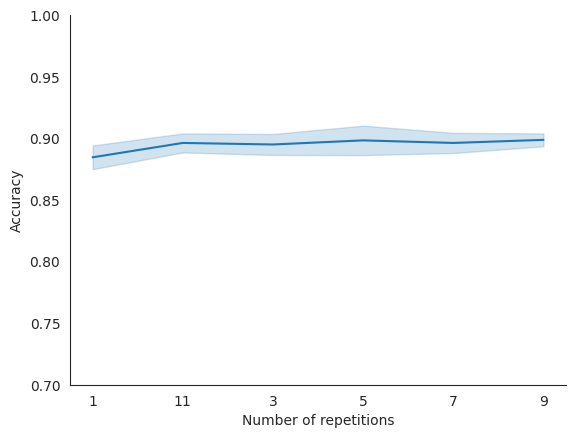

In [256]:
#creating lineplot, one score, avg +- std deviations over all seeds

score = 'acc_mean'
method = 'divcurves_shortest_path_distance'


data_score = res.loc[(method, slice(None)), (score, slice(None))]
data_score = pd.DataFrame(data_score.loc['divcurves_shortest_path_distance',(score, slice(None))])
data_score_long = pd.melt(data_score, value_name=score, col_level=1, var_name='n_reps')

# data = pd.concat(data_score_long, axis=1)
sns.set_style("white")
sns.despine()
ax = sns.lineplot(data_score_long, x='n_reps', y=score, estimator=np.mean, errorbar='sd')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_ylim(0.7, 1)

ax.set_xlabel('Number of repetitions')

ax.set_ylabel('Accuracy')

score = 'silh_mean'
method = 'divcurves_shortest_path_distance'


data_score = res.loc[(method, slice(None)), (score, slice(None))]
data_score = pd.DataFrame(data_score.loc['divcurves_shortest_path_distance',(score, slice(None))])
data_score_long = pd.melt(data_score, value_name=score, col_level=1, var_name='n_reps')

# data = pd.concat(data_score_long, axis=1)
sns.set_style("white")
sns.despine()
sns.lineplot(data_score_long, x='n_reps', y=score, estimator=np.mean, errorbar='sd', ax=ax)


In [220]:
list(avg_scores_df.loc[method,(score, slice(None))])

[0.4224120201636271, 0.42554801371834483, 0.42875695887157084]

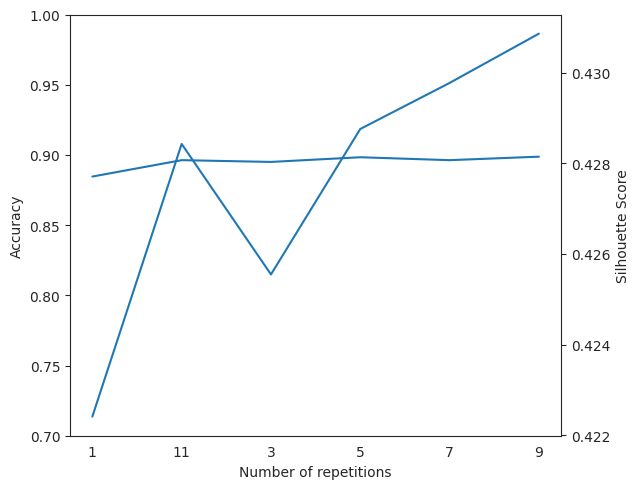

In [257]:
# with pyplotlib
score = 'acc_mean'
method = 'divcurves_shortest_path_distance'

x = n_reps
y_score = list(avg_scores_df.loc[method,(score, slice(None))])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
ax.plot(x, y_score)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_ylim(0.7, 1)

ax.set_xlabel('Number of repetitions')

ax.set_ylabel('Accuracy')

ax2 = ax.twinx()
score2 = 'silh_mean'
ax2.set_ylabel('Silhouette Score')
ax2.plot(x, list(avg_scores_df.loc[method,(score2, slice(None))]))

fig.tight_layout()
plt.show()


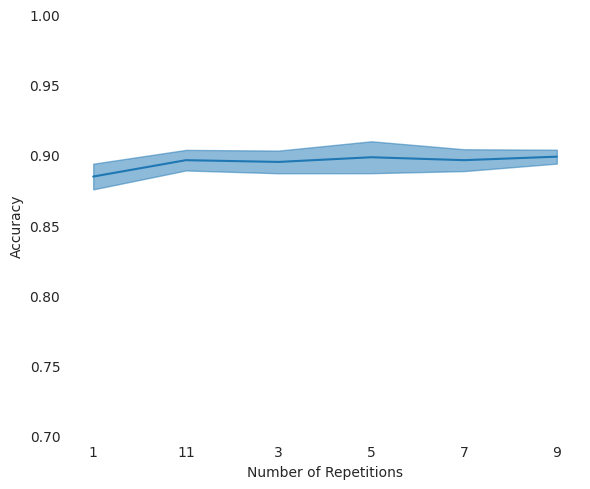

In [266]:
# with pyplotlib
scores = ['acc_mean', 'silh_mean']
method = 'divcurves_shortest_path_distance'
colors = ['tab:blue', 'tab:orange']

x = n_reps
axes = {}

fig, axes[0] = plt.subplots(ncols=1, nrows=1, figsize=(6,5))
axes[1] = ax.twinx()

y = {}
y_errs = {}

for i, score in enumerate(scores):
    y = np.array(avg_scores_df.loc[method,(score, slice(None))])
    y_errs = np.array(std_scores_df.loc[method,(score, slice(None))])

    axes[i].plot(x, y, color=colors[i], label=score)
    axes[i].fill_between(x, y-y_errs, y+y_errs, color=colors[i], alpha=0.5)

    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].spines['bottom'].set_visible(False)
    axes[i].spines['left'].set_visible(False)

axes[0].set_ylim(0.7, 1)
axes[0].set_xlabel('Number of Repetitions')
axes[0].set_ylabel('Accuracy')
axes[1].set_ylim(0.35, 0.45)
axes[1].set_ylabel('Silhouette Score')

# ask matplotlib for the plotted objects and their labels
lines, labels = axes[0].get_legend_handles_labels()
lines2, labels2 = axes[1].get_legend_handles_labels()
axes[1].legend(lines + lines2, labels + labels2, loc=0)

fig.tight_layout()
plt.show()
